# Step 1 — PPO with continuous actions (sanity check on Pendulum)

Starting point: our PPO from the course (TD6, discrete actions on LunarLander).
EvoGym robots need one **real number per actuator** at every step, so the policy must output continuous actions.

Changes vs TD6 (marked `# CHANGED` / `# ADDED` in the code):
1. **Network**: the actor head outputs the mean μ of a Gaussian (no softmax) + a learned `log_std` parameter.
2. **Distribution**: `Normal(μ, σ)` instead of `Categorical`; log-probs and entropy are **summed** over action dimensions.
3. **Action bounds**: the policy acts around [-1, 1]; actions are clipped and rescaled to the env bounds just before `env.step`. The buffer stores the **unclipped** action so the PPO ratio stays correct.
4. **Test**: deterministic action = μ (instead of `argmax`).
5. **Hyperparameters**: TD6 defaults, `entropy_beta = 0` (σ already drives exploration).

Why Pendulum first: 1 continuous action, trains in minutes, known target (random ≈ −1200 to −1600 per episode, solved ≈ −200).
If PPO fails here, the bug is in PPO, not in EvoGym.

The PPO code lives in [`ppo.py`](../ppo.py) at the repo root (`# CHANGED` / `# ADDED` mark the differences with TD6). This notebook imports it and runs the Pendulum experiments.

In [1]:
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch

import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from pathlib import Path

import sys
sys.path.insert(0, "..")  # repo root, where ppo.py lives
from ppo import ActorCriticNetwork, PPOAgent, to_env_action, RunningMeanStd, make_vec_env, train_agent, test_agent

## Self-checks

In [2]:
# Self-check: the bounds map to the env bounds
_space = gym.spaces.Box(-2.0, 2.0, (1,))
assert np.allclose(to_env_action(np.array([-1.0]), _space), -2.0)
assert np.allclose(to_env_action(np.array([5.0]), _space), 2.0)   # clipped
assert np.allclose(to_env_action(np.array([0.0]), _space), 0.0)

# Self-check against numpy on random data fed in chunks
_rms, _data = RunningMeanStd(), np.random.randn(1000) * 3 + 5
for chunk in np.split(_data, 10):
    _rms.update(chunk)
assert abs(_rms.mean - _data.mean()) < 1e-3 and abs(_rms.var - _data.var()) < 1e-2

# Vectorised GAE (T, n_envs) == TD6 scalar recursion, column by column
_ag = PPOAgent(state_size=3, action_size=1)
_rng = np.random.default_rng(0)
_R, _V, _D, _nv = _rng.normal(size=(7, 2)), _rng.normal(size=(7, 2)), _rng.random((7, 2)) < 0.3, _rng.normal(size=2)
_ag.rewards, _ag.values, _ag.dones = list(_R), list(_V), list(_D)
_ret, _adv = _ag.compute_gae(_nv)
for j in range(2):
    gae, ref = 0.0, np.zeros(7)
    vals = np.append(_V[:, j], _nv[j])
    for t in reversed(range(7)):
        delta = _R[t, j] + 0.99 * vals[t + 1] * (1 - _D[t, j]) - vals[t]
        gae = delta + 0.99 * 0.95 * (1 - _D[t, j]) * gae
        ref[t] = gae
    assert np.allclose(_adv[:, j], ref, atol=1e-5) and np.allclose(_ret[:, j], ref + _V[:, j], atol=1e-5)
print("self-checks passed")

Using device: cpu


self-checks passed


## Plotting (reused from TD6)

In [3]:
def _moving_avg(x, window):
    """Return the moving average aligned with the original sample indices."""
    x = np.asarray(x, dtype=float)
    if len(x) < window or window == 1:
        return np.arange(len(x)), x
    moving_avg = np.convolve(x, np.ones(window) / window, mode="valid")
    return np.arange(window - 1, len(x)), moving_avg


def plot_results(
    rewards,
    actor_losses=None,
    critic_losses=None,
    reward_window=100,
    loss_window=100,
    solved_y=200,
    save_path=None,
    loss_log_scale=False,
):
    """Plot raw curves on the left and moving averages on the right.

    Rewards are recorded per episode; losses are recorded per agent update.
    Short histories are displayed without smoothing.
    """
    if reward_window < 1 or loss_window < 1:
        raise ValueError("Moving-average windows must be positive.")

    rows = [(rewards, "Train Reward", "Episode", "Total Reward", "Avg Reward", reward_window)]
    if actor_losses is not None:
        rows.append((actor_losses, "Actor Loss", "Update", "Loss", "Avg Loss", loss_window))
    if critic_losses is not None:
        rows.append((critic_losses, "Critic Loss", "Update", "Loss", "Avg Loss", loss_window))

    fig, axes = plt.subplots(len(rows), 2, figsize=(14, 4.6 * len(rows)), squeeze=False)

    for row, (values, title, xlabel, ylabel, avg_ylabel, window) in enumerate(rows):
        raw_ax, avg_ax = axes[row]

        # Raw values (left column).
        raw_ax.plot(values, alpha=0.4)
        raw_ax.set_title(f"{title} per {xlabel}")
        raw_ax.set_ylabel(ylabel)

        # Moving average (right column), aligned with the original indices.
        indices, moving_avg = _moving_avg(values, window)
        avg_ax.plot(indices, moving_avg)
        if len(values) >= window and window > 1:
            avg_ax.set_title(f"Moving Avg {title} (window={window})")
        else:
            avg_ax.set_title(f"{title} (no smoothing)")
        avg_ax.set_ylabel(avg_ylabel)

        for ax in (raw_ax, avg_ax):
            ax.set_xlabel(xlabel)
            ax.grid(True)
            if row == 0:
                if solved_y is not None:
                    ax.axhline(solved_y, color="gray", linestyle="--", linewidth=1,
                               label=f"Reward reference ({solved_y:g})")
                    ax.legend()
            else:
                ax.axhline(0, color="gray", linestyle="--", linewidth=1)
                if loss_log_scale:
                    # Actor losses may be negative, so a signed log scale is needed.
                    ax.set_yscale("symlog")

    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150)
    plt.show()


## Run: Pendulum, TD6 hyperparameters, 200k steps (8 parallel envs, ≈ 1000 episodes)

State size: 3, Action size: 1, bounds [-2.]..[2.], 8 envs (sync)
Using device: cpu


Steps   12,288 | Ep 56: Avg100 = -1249.5, sigma = 1.012


Steps   22,528 | Ep 112: Avg100 = -1253.6, sigma = 0.973


Steps   30,720 | Ep 152: Avg100 = -1243.0, sigma = 0.973


Steps   40,960 | Ep 200: Avg100 = -1242.4, sigma = 0.940


Steps   51,200 | Ep 256: Avg100 = -1213.7, sigma = 0.943


... (11 outputs left out)

Steps  172,032 | Ep 856: Avg100 = -434.0, sigma = 0.491


Steps  182,272 | Ep 904: Avg100 = -363.2, sigma = 0.450


Steps  190,464 | Ep 952: Avg100 = -327.9, sigma = 0.435


Steps  200,704 | Ep 1000: Avg100 = -475.5, sigma = 0.435
Training complete!

Final avg (last 100): -475.5
Max reward: -4.2


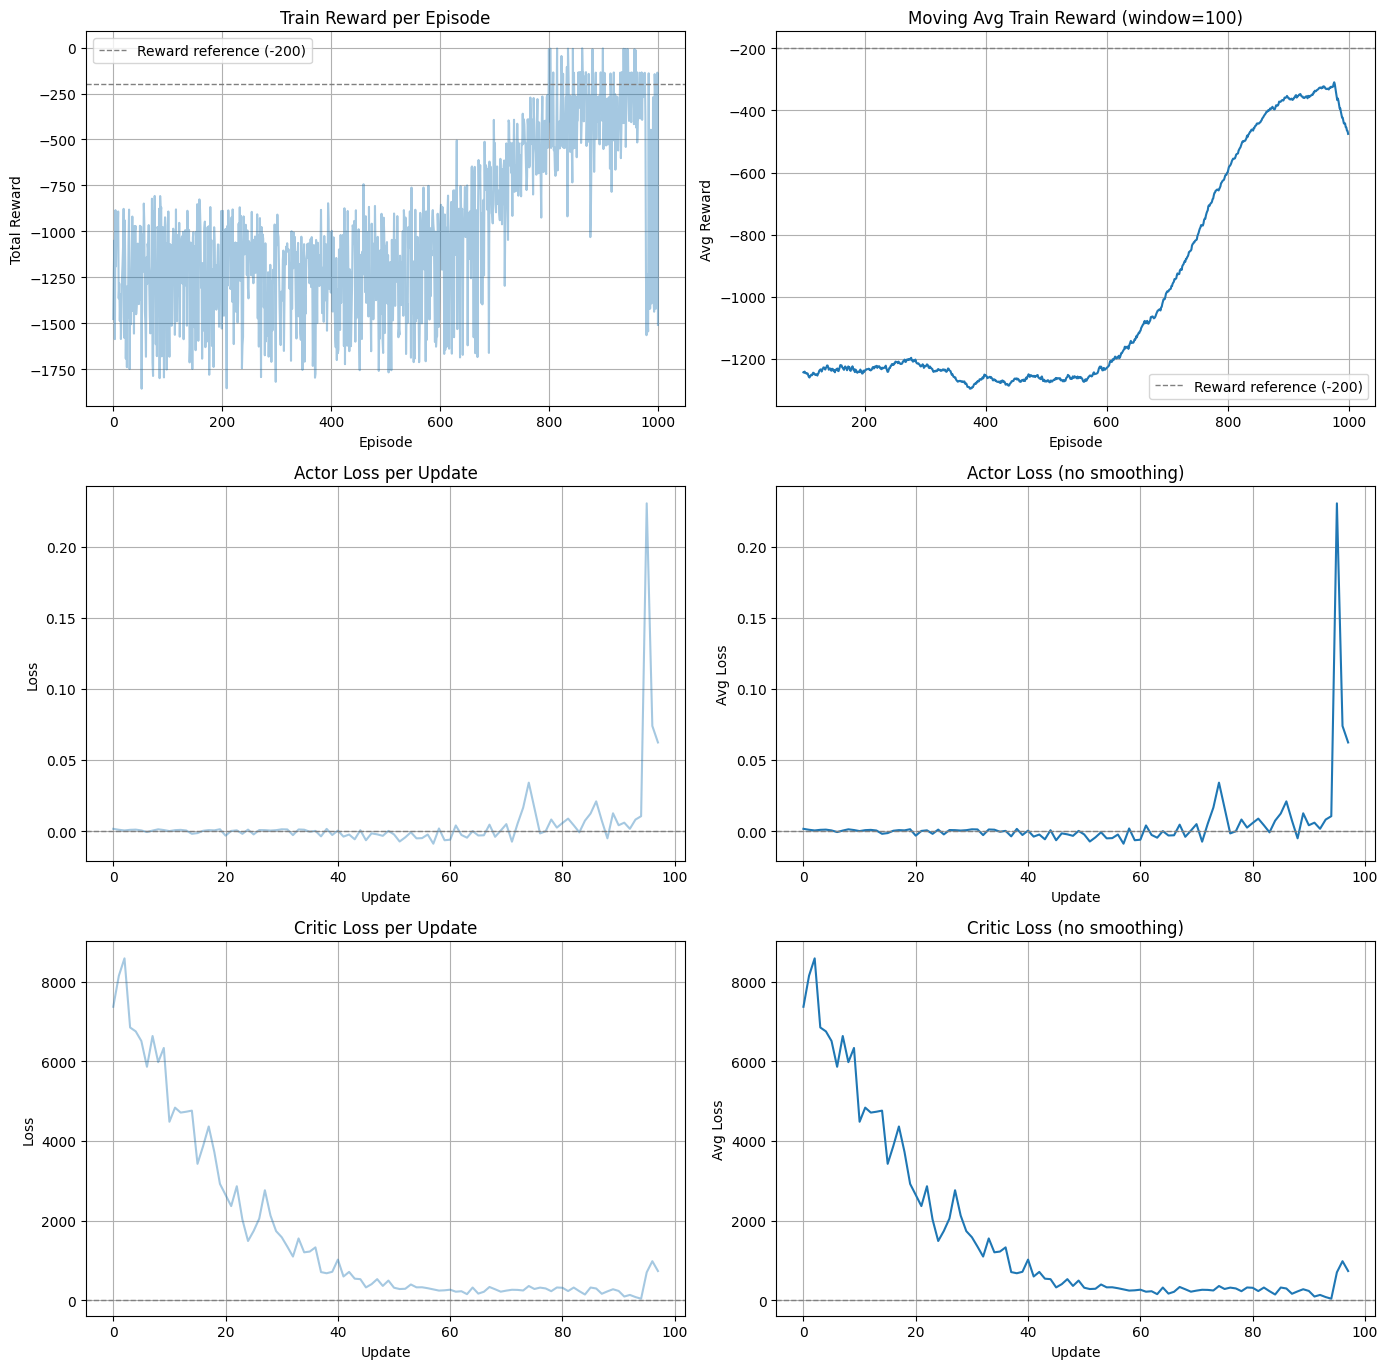

In [4]:
seed = 31
agent, rewards, actor_losses, critic_losses, stds = train_agent(
    total_steps=200_000, update_freq=2048, n_envs=8, vectorization="sync", env_id="Pendulum-v1", seed=seed,
    lr=3e-4, gamma=0.99, gae_lambda=0.95, entropy_beta=0.0,
    clip_epsilon=0.2, ppo_epochs=10, batch_size=64,
)
print(f"\nFinal avg (last 100): {np.mean(rewards[-100:]):.1f}")
print(f"Max reward: {max(rewards):.1f}")

Path("../figures").mkdir(exist_ok=True)
plot_results(rewards, actor_losses=actor_losses, critic_losses=critic_losses,
             solved_y=-200, save_path="../figures/01_pendulum_td6_defaults.png")

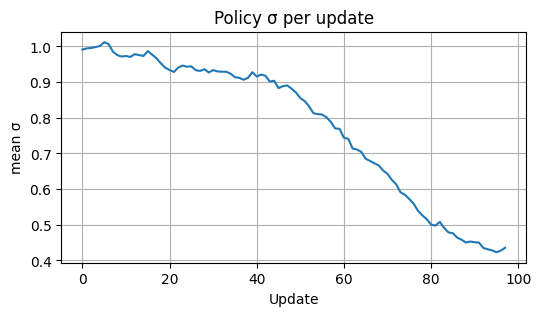

Test Episode 1: -132.1
Test Episode 2: -4.4
Test Episode 3: -1545.2
Test Episode 4: -257.6
Test Episode 5: -395.3
Mean test return: -466.9


In [5]:
plt.figure(figsize=(6, 3))
plt.plot(stds)
plt.title("Policy σ per update")
plt.xlabel("Update"); plt.ylabel("mean σ"); plt.grid(True)
plt.show()

test_scores = test_agent(agent, episodes=5)
print(f"Mean test return: {np.mean(test_scores):.1f}")

## Experiment 1: reward normalisation

**Observation (run above):** nothing happens for ~600 episodes, the critic loss starts around 8,000, and training collapses at the end.
**Hypothesis:** the critic cannot fit returns of that scale quickly, so advantages are noisy. Rescaling rewards should make learning start earlier and be more stable.
**Protocol:** same TD6 hyperparameters, 200k steps (8 parallel envs), 3 seeds, with vs without reward normalisation. One change only.

In [6]:
SEEDS = [31, 32, 33]
results = {}
for norm in [False, True]:
    for s in SEEDS:
        _, r, _, cl, sd = train_agent(total_steps=200_000, n_envs=8, vectorization="sync", env_id="Pendulum-v1", seed=s,
                                      norm_reward=norm, verbose=False)
        results[(norm, s)] = {"rewards": np.array(r), "critic_loss": np.array(cl), "sigma": np.array(sd)}
        print(f"norm_reward={norm!s:5} seed={s}: last100 = {np.mean(r[-100:]):7.1f} | "
              f"best avg100 = {max(np.convolve(r, np.ones(100) / 100, 'valid')):7.1f}")

Using device: cpu


norm_reward=False seed=31: last100 =  -475.5 | best avg100 =  -309.2
Using device: cpu


norm_reward=False seed=32: last100 =  -416.2 | best avg100 =  -350.1
Using device: cpu


norm_reward=False seed=33: last100 =  -909.8 | best avg100 =  -503.7
Using device: cpu


norm_reward=True  seed=31: last100 =  -172.1 | best avg100 =  -146.7
Using device: cpu


norm_reward=True  seed=32: last100 =  -180.8 | best avg100 =  -149.1
Using device: cpu


norm_reward=True  seed=33: last100 =  -176.7 | best avg100 =  -144.0


,reward_norm,seed,last100,best_avg100,episodes_to_-400
0,False,31,-475.5,-309.2,868.0
1,False,32,-416.2,-350.1,860.0
2,False,33,-909.8,-503.7,NaN
3,True,31,-172.1,-146.7,208.0
4,True,32,-180.8,-149.1,225.0
5,True,33,-176.7,-144.0,204.0


last100        best_avg100       
               mean    std        mean    std
reward_norm                                  
False        -600.5  269.5      -387.7  102.5
True         -176.5    4.4      -146.6    2.6

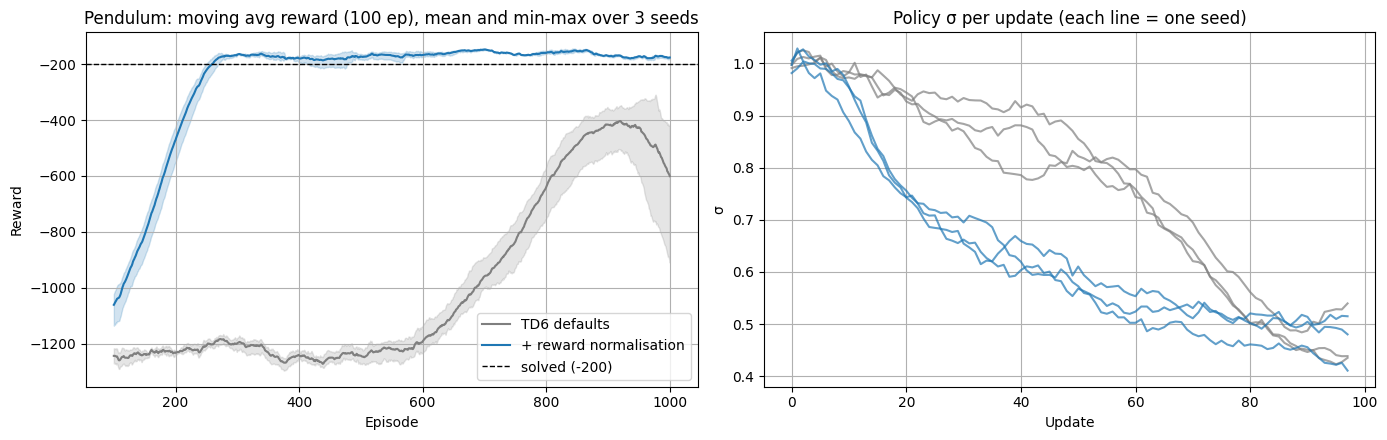

In [7]:
import pandas as pd

def first_episode_above(r, threshold=-400, window=100):
    avg = np.convolve(r, np.ones(window) / window, "valid")
    hit = np.flatnonzero(avg > threshold)
    return int(hit[0] + window) if len(hit) else None

rows = []
for (norm, s), d in results.items():
    r = d["rewards"]
    rows.append({"reward_norm": norm, "seed": s,
                 "last100": np.mean(r[-100:]),
                 "best_avg100": np.convolve(r, np.ones(100) / 100, "valid").max(),
                 "episodes_to_-400": first_episode_above(r)})
table = pd.DataFrame(rows)
display(table.round(1))
display(table.groupby("reward_norm")[["last100", "best_avg100"]].agg(["mean", "std"]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for norm, color, label in [(False, "tab:gray", "TD6 defaults"), (True, "tab:blue", "+ reward normalisation")]:
    curves = np.array([np.convolve(results[(norm, s)]["rewards"], np.ones(100) / 100, "valid") for s in SEEDS])
    x = np.arange(100, 100 + curves.shape[1])
    axes[0].plot(x, curves.mean(0), color=color, label=label)
    axes[0].fill_between(x, curves.min(0), curves.max(0), color=color, alpha=0.2)
    for s in SEEDS:
        axes[1].plot(results[(norm, s)]["sigma"], color=color, alpha=0.7)
axes[0].axhline(-200, color="k", ls="--", lw=1, label="solved (-200)")
axes[0].set(title="Pendulum: moving avg reward (100 ep), mean and min-max over 3 seeds", xlabel="Episode", ylabel="Reward")
axes[1].set(title="Policy σ per update (each line = one seed)", xlabel="Update", ylabel="σ")
axes[0].legend(); axes[0].grid(True); axes[1].grid(True)
plt.tight_layout()
plt.savefig("../figures/01_pendulum_reward_norm.png", dpi=120)
plt.show()